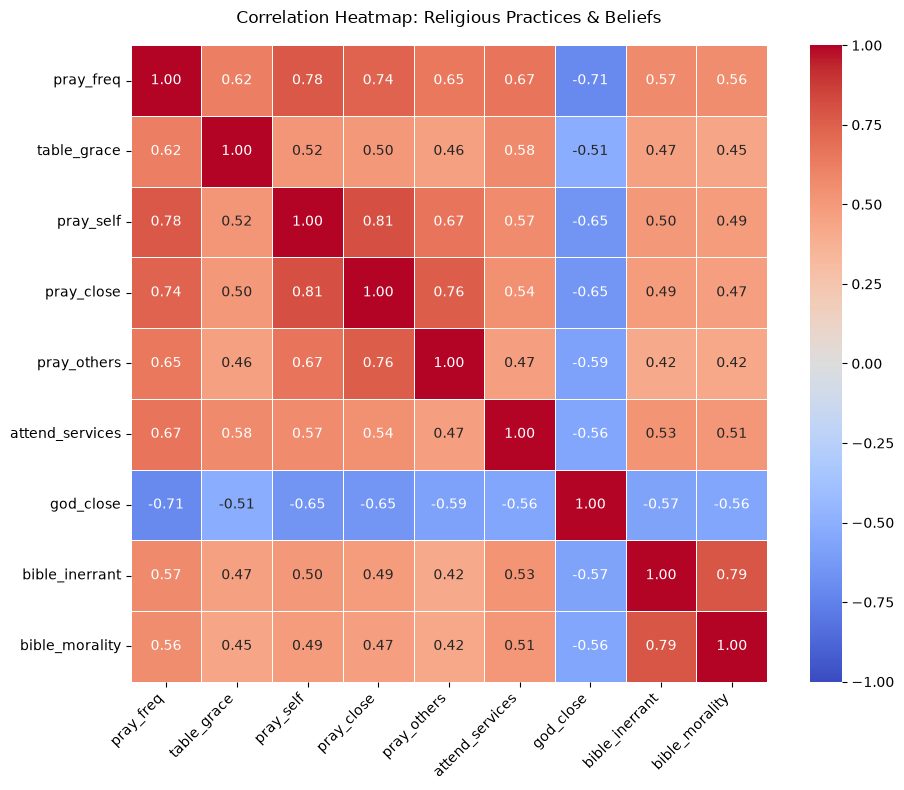

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_stata("chrisu.DTA", convert_categoricals=False)

# map variable codes to readable labels
var_mapping = {
    # religious practices
    "V25": "pray_freq",  # About how often do you pray?
    "V26": "table_grace",  # Table prayers of grace before/after meals
    "V27": "pray_self",  # Pray about own personal needs
    "V28": "pray_close",  # Pray about needs of people close to you
    "V29": "pray_others",  # Pray about needs of others / current affairs
    "V34": "attend_services",  # How often do you attend religious services now?
    # religious beliefs
    "V30": "god_close",  # How close do you feel to God most of the time?
    "V39": "bible_inerrant",  # Bible contains no errors / infallible Word of God
    "V41": "bible_morality",  # Bible is the final and complete guide to morality
}

# subset and rename columns
subset_df = df[list(var_mapping.keys())].rename(columns=var_mapping)

# correlation matrix --> spearman correlation
corr_matrix = subset_df.corr(method="pearson")

# correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
)

plt.title("Correlation Heatmap: Religious Practices & Beliefs", pad=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:

import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from plotnine import *
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# could not find chris.dta fro some reason -- locate and load chrisu.dta automatically
skip_dirs = {".venv", "venv", "node_modules", ".git", ".Trash", "Applications", ".cache", "__pycache__"}
search_roots = [
    Path.cwd(),
    Path.home() / "Desktop",
    Path.home() / "Documents",
    Path.home() / "Downloads",
    Path.home() / "Library" / "Mobile Documents",
]

matches = []
for root in search_roots:
    if not root.exists():
        continue
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in skip_dirs and not d.startswith(".")]
        for fname in filenames:
            if fname.lower() == "chrisu.dta":
                matches.append(Path(dirpath) / fname)

if not matches:
    raise FileNotFoundError(
        "Could not find chrisu.dta in the current directory, Desktop, Documents, Downloads, or iCloud Drive."
    )


data_path = next(
    (p for p in matches if "religion_logit" in str(p).lower()),
    matches[0],
)
print(f"Loaded file: {data_path}\n")

# convert_categoricals=False keeps underlying numeric codes from stata (.dta)
raw_df = pd.read_stata(data_path, convert_categoricals=False)

# prep variables
var_map = {
    # religious practices
    "V25": "pray_freq",
    "V26": "table_grace",
    "V27": "pray_self",
    "V28": "pray_close",
    "V29": "pray_others",
    "V34": "attend_services",
    # religious beliefs
    "V30": "god_close",
    "V39": "bible_inerrant",
    "V41": "bible_moral_code",
}

df = raw_df[list(var_map.keys())].rename(columns=var_map).copy()
cols = list(var_map.values())

for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

work = df.dropna(subset=cols).copy()
print(f"Complete cases retained: {len(work)} of {len(df)}\n")
print("=== Summary Statistics ===")
print(work[cols].describe().round(2))

# normalise varibles -- scale (mean 0, SD 1) and fit PCA
X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

pc_names = [f"PC{i}" for i in range(1, len(cols) + 1)]
prop = pca.explained_variance_ratio_

variance_table = pd.DataFrame(
    {
        "Standard deviation": pca.explained_variance_ ** 0.5,
        "Proportion of variance": prop,
        "Cumulative proportion": prop.cumsum(),
    },
    index=pc_names,
).T.round(3)

Loaded file: /Users/elavainikrishnamoorthy/Desktop/hs4002_ay26/hs4002labs_2026/project/religion_logit/chrisu.DTA

Complete cases retained: 3034 of 3530

=== Summary Statistics ===
       pray_freq  table_grace  pray_self  pray_close  pray_others  attend_services  god_close  bible_inerrant  bible_moral_code
count    3034.00      3034.00    3034.00      3034.0      3034.00          3034.00    3034.00         3034.00           3034.00
mean        2.40         1.43       2.01         2.1         1.62             2.65       2.49            3.03              3.06
std         1.67         1.22       1.38         1.4         1.29             1.82       1.19            1.45              1.39
min         0.00         0.00       0.00         0.0         0.00             0.00       1.00            1.00              1.00
25%         1.00         1.00       1.00         1.0         1.00             1.00       2.00            2.00              2.00
50%         3.00         1.00       2.00         2.0

In [24]:
#loadings table
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

loadings = pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=pc_names,
)
print("=== Component Loadings ===")
print(loadings.round(3))

=== Component Loadings ===
                    PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8    PC9
pray_freq         0.377 -0.103  0.116 -0.214  0.050 -0.224  0.762  0.224  0.323
table_grace       0.295  0.051  0.739  0.400 -0.402 -0.148 -0.127 -0.056 -0.030
pray_self         0.357 -0.282 -0.125 -0.078  0.224 -0.572 -0.115 -0.091 -0.611
pray_close        0.354 -0.358 -0.228  0.147  0.097 -0.134 -0.436 -0.129  0.662
pray_others       0.320 -0.392 -0.262  0.445 -0.127  0.572  0.215  0.108 -0.275
attend_services   0.332  0.104  0.403 -0.239  0.655  0.448 -0.152 -0.064 -0.047
god_close        -0.341 -0.004  0.081  0.672  0.575 -0.219  0.198  0.048  0.071
bible_inerrant    0.311  0.547 -0.235  0.158  0.027 -0.079 -0.219  0.685 -0.018
bible_moral_code  0.303  0.562 -0.281  0.185 -0.013 -0.007  0.208 -0.660  0.012


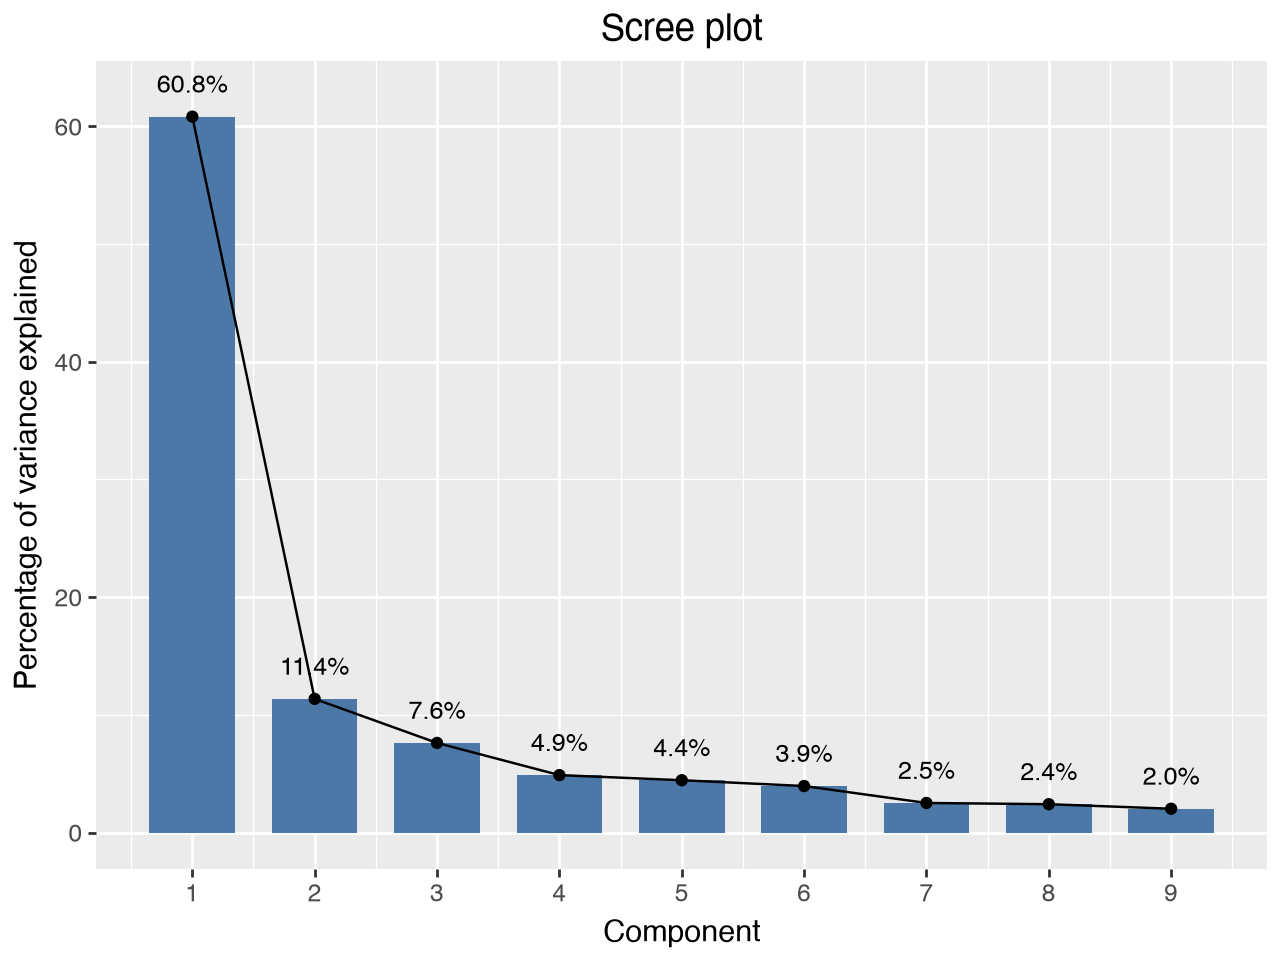

In [25]:
#scree plot
scree = pd.DataFrame(
    {
        "component": range(1, len(cols) + 1),
        "percent": pca.explained_variance_ratio_ * 100,
    }
)
scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")

scree_plot = (
    ggplot(scree, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + scale_x_continuous(breaks=range(1, len(cols) + 1))
    + labs(
        x="Component",
        y="Percentage of variance explained",
        title="Scree plot",
    )
)

scree_plot.save("scree_plot.png", dpi=300)
scree_plot

In [26]:
import statsmodels.formula.api as smf

work['PC1'] = pca.transform(X)[:, 0]

In [ ]:
early_first_sex = work['first_sex_code'].between(1, 3)    # codes 1-3 = under 15, 15, 16 (assumed mapping: code 1 is “Under 15” and code 9 is “22 or more”, then codes 2 to 8 are seven categories between - natural reading = 15 to 21)
deviant = (early_first_sex |
           (work['sex_partners_yr'] >= 1) |
           (work['sex_partners_lifetime'] >= 1) |
           (work['unprotected_sex_stranger'] >= 0))
# old thresholds aligned with christian fundamentalism           

In [30]:
sex_items = ['first_sex_code', 'sex_partners_yr', 'sex_partners_lifetime', 'unprotected_sex_stranger']
work['deviant'] = np.where(work[sex_items].isna().all(axis=1), np.nan, deviant.astype(float))
print(work['deviant'].value_counts(dropna=False))

deviant
1.0    2988
NaN      42
0.0       4
Name: count, dtype: int64


In [ ]:
# reverse so HIGHER = CLOSER to God 
work["god_close"] = 6 - work["god_close"]

work["gender"] = work["gender"].map({1: "Male", 2: "Female"})
work["race"] = work["race"].map(
    {1: "White", 2: "Black", 3: "Hispanic", 4: "Asian/Pacific Islander", 5: "Other"}
)

# keep respondents with complete data on everything in model
model_df = work.dropna(subset=['deviant', 'PC1', 'gender_code', 'race_code']).copy()
print('N in model:', len(model_df))

KeyError: 'gender'

In [11]:
logit_dev = smf.logit('deviant ~ PC1 + sex_woman + race_cat', data=model_df).fit(maxiter=100)
print(logit_dev.summary())

Optimization terminated successfully.
         Current function value: 0.007806
         Iterations 37


LinAlgError: Singular matrix

In [ ]:
# rebuild outcome with new stricter thresholds; the old thresholds fail because only 4 of 2,928 are non-deviant
# people are coded 0, spread across a few race categories, so the model can't be estimated
deviant = (work['first_sex_code'].between(1, 3) |       # first sex under 15, 15 or 16 (assumed mapping)
           (work['sex_partners_yr'] >= 3) |
           (work['sex_partners_lifetime'] >= 5) |
           (work['unprotected_sex_stranger'] >= 1))
work['deviant'] = np.where(work[sex_items].isna().all(axis=1), np.nan, deviant.astype(float))

# rebuild model_df from work
model_df = work.dropna(subset=['deviant', 'PC1', 'gender_code', 'race_code']).copy()
print('Share coded deviant:', round(model_df['deviant'].mean(), 3))   # should print about 0.364

logit_dev = smf.logit('deviant ~ sex_woman + race_cat + PC1', data=model_df).fit()
print(logit_dev.summary())

Share coded deviant: 0.363
Optimization terminated successfully.
         Current function value: 0.630510
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                deviant   No. Observations:                 2952
Model:                          Logit   Df Residuals:                     2945
Method:                           MLE   Df Model:                            6
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                 0.03797
Time:                        23:20:04   Log-Likelihood:                -1861.3
converged:                       True   LL-Null:                       -1934.7
Covariance Type:            nonrobust   LLR p-value:                 3.455e-29
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -0.3782      0.069     -5.467      0.

In [ ]:
logit_dev = smf.logit('deviant ~ sex_woman + race_cat + PC1', data=model_df).fit()
print(logit_dev.summary())

from stargazer.stargazer import Stargazer

# reograninsing so the controls appear first before pc1's row of estimates
sg = Stargazer([logit_dev])
sg.title('Sexual Deviance')
sg.custom_columns(['Logit'], [1])
sg.covariate_order(['sex_woman[T.Woman]', 'PC1', 'Intercept'])
sg.rename_covariates({
    'sex_woman[T.Woman]': 'Woman',
    'race_cat[T.Black]': 'Black',
    'race_cat[T.Hispanic]': 'Hispanic',
    'race_cat[T.Asian_PI]': 'Asian/Pacific Islander',
    'race_cat[T.Other]': 'Other race',
})

sg


Optimization terminated successfully.
         Current function value: 0.630718
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                deviant   No. Observations:                 2928
Model:                          Logit   Df Residuals:                     2921
Method:                           MLE   Df Model:                            6
Date:                Sun, 15 Nov 2026   Pseudo R-squ.:                 0.03786
Time:                        10:49:36   Log-Likelihood:                -1846.7
converged:                       True   LL-Null:                       -1919.4
Covariance Type:            nonrobust   LLR p-value:                 7.536e-29
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -0.3822      0.069     -5.503      0.000      -0.518      -0.246

on average, an one unit increase in an indivudal displaying behaviours representative of PC1 is expected to cause a 0.163 decrease in log odds of engaging in sexually devinat behaviour.  

In [18]:
!pip install marginaleffects
from marginaleffects import avg_comparisons, comparisons
avg_comparisons(logit_dev, variables=['PC1', 'sex_woman', 'race_cat'])
comparisons(logit_dev, variables='PC1', newdata='mean')



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""PC1""","""+1""",-0.036682,0.003804,-9.644214,0.0,inf,-0.04414,-0.029224


on average, a one-unit increase in PC1 (individual subscribing to orthodox Christian rpinciples and practices) is associated with a 3.7 percentage decrease in the probability of engaging in sexually deviant behaviours, ceteris paribus (p < .001).

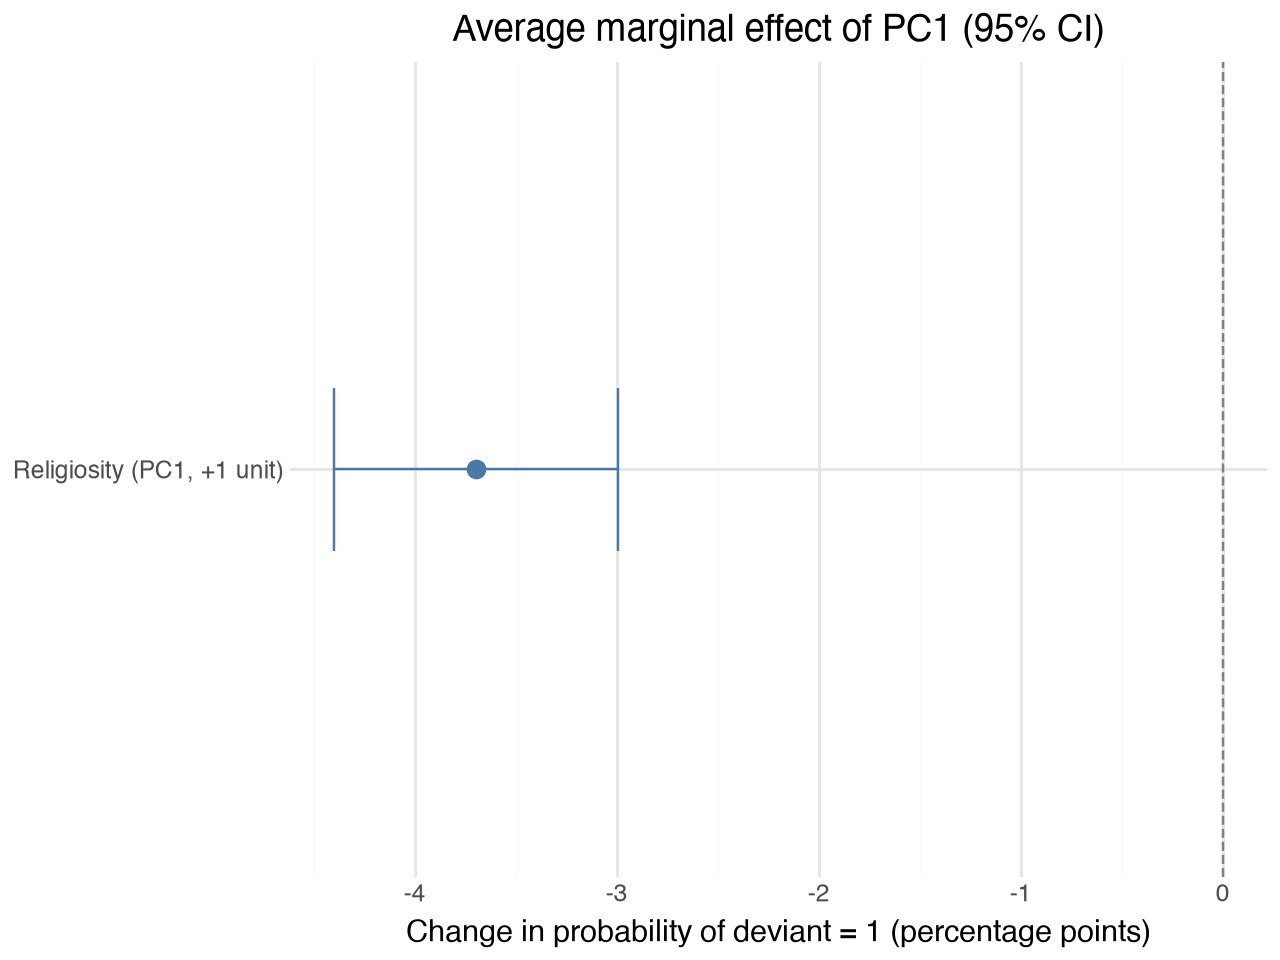

In [69]:
from plotnine import *
from marginaleffects import avg_comparisons

# Average marginal effect of PC1 only (controls stay in the model, not in the graph)
ame_df = avg_comparisons(logit_dev, variables='PC1').to_pandas()

# Label
ame_df['label'] = 'Religiosity (PC1, +1 unit)'

# Convert probabilities to percentage points
ame_df['pp'] = ame_df['estimate'] * 100
ame_df['lo'] = ame_df['conf_low'] * 100
ame_df['hi'] = ame_df['conf_high'] * 100

(
    ggplot(ame_df, aes(x='pp', y='label'))
    + geom_vline(xintercept=0, linetype='dashed', color='grey')   # no-effect line
    + geom_errorbarh(aes(xmin='lo', xmax='hi'), height=0.2, color='#4C78A8')
    + geom_point(size=3, color='#4C78A8')
    + labs(x='Change in probability of deviant = 1 (percentage points)', y='',
           title='Average marginal effect of PC1 (95% CI)')
    + theme_minimal()
)

coding with separate independent varaibles and no pc1

In [33]:
import statsmodels.formula.api as smf

var_map = {
    'V25': 'pray_freq', 'V26': 'table_grace', 'V27': 'pray_self',
    'V28': 'pray_close', 'V29': 'pray_others', 'V34': 'attend_services',
    'V30': 'god_close', 'V39': 'bible_inerrant', 'V41': 'bible_morality',   # V32 left out
}
dev_map = {
    'V81': 'first_sex_code', 'V82': 'sex_partners_yr',
    'V83': 'sex_partners_lifetime', 'V86': 'unprotected_sex_stranger',
}
ctrl_map = {'V3': 'gender_code', 'V2': 'race_code'}

reg_df = raw_df[list(var_map) + list(dev_map) + list(ctrl_map)].rename(
    columns={**var_map, **dev_map, **ctrl_map}).copy()
for c in reg_df.columns:
    reg_df[c] = pd.to_numeric(reg_df[c], errors='coerce')

# V30 is coded 1 = very close ... 5 = no closeness; reverse so higher = closer to God,
# the same direction as the other items
reg_df['god_close'] = 6 - reg_df['god_close']

rel_vars = list(var_map.values())
sex_items = list(dev_map.values())

In [34]:
deviant = (reg_df['first_sex_code'].between(1, 3) |       # first sex under 15, 15 or 16 (assumed mapping)
           (reg_df['sex_partners_yr'] >= 3) |
           (reg_df['sex_partners_lifetime'] >= 5) |
           (reg_df['unprotected_sex_stranger'] >= 1))

# Missing on all four items stays missing; True/False becomes 1/0
reg_df['deviant'] = np.where(reg_df[sex_items].isna().all(axis=1), np.nan, deviant.astype(float))

In [35]:
reg_df['sex_woman'] = pd.Categorical(
    np.where(reg_df['gender_code'] == 2, 'Woman', 'Not Woman'),
    categories=['Not Woman', 'Woman']
)
reg_df['race_cat'] = pd.Categorical(
    reg_df['race_code'].map({1: 'White', 2: 'Black', 3: 'Hispanic', 4: 'Asian_PI', 5: 'Other'}),
    categories=['White', 'Black', 'Hispanic', 'Asian_PI', 'Other']
)

# Complete cases on everything in the model
model_df = reg_df.dropna(subset=rel_vars + ['deviant', 'gender_code', 'race_code']).copy()
print('N in model:', len(model_df))
print('Share coded deviant:', round(model_df['deviant'].mean(), 3))

N in model: 2952
Share coded deviant: 0.363


In [67]:
formula = 'deviant ~ ' + ' + '.join(rel_vars) + ' + sex_woman + race_cat'
logit_items = smf.logit(formula, data=model_df).fit()

# Estimates table: religiosity items only (controls stay in the model, just not displayed)
ci = logit_items.conf_int().loc[rel_vars]
est_table = pd.DataFrame({
    'coef': logit_items.params[rel_vars],
    'std err': logit_items.bse[rel_vars],
    'z': logit_items.tvalues[rel_vars],
    'P>|z|': logit_items.pvalues[rel_vars],
    '[0.025': ci[0],
    '0.975]': ci[1],
}).round(3)

print('Dep. Variable: deviant | N =', int(logit_items.nobs),
      '| Pseudo R-squ. =', round(logit_items.prsquared, 4),
      '| Log-Likelihood =', round(logit_items.llf, 1))
print('Controls (not shown): gender, race')
est_table

Optimization terminated successfully.
         Current function value: 0.619606
         Iterations 5
Dep. Variable: deviant | N = 2952 | Pseudo R-squ. = 0.0546 | Log-Likelihood = -1829.1
Controls (not shown): gender, race


,coef,std err,z,P>|z|,[0.025,0.975]
pray_freq,-0.154,0.046,-3.344,0.001,-0.244,-0.064
table_grace,-0.046,0.045,-1.021,0.307,-0.134,0.042
pray_self,-0.043,0.053,-0.818,0.413,-0.147,0.060
pray_close,0.034,0.055,0.620,0.535,-0.074,0.142
pray_others,0.099,0.048,2.058,0.040,0.005,0.193
attend_services,-0.204,0.032,-6.304,0.000,-0.268,-0.141
god_close,0.072,0.050,1.455,0.146,-0.025,0.170
bible_inerrant,0.030,0.047,0.632,0.527,-0.062,0.122
bible_morality,-0.035,0.048,-0.735,0.462,-0.129,0.059


In [71]:
from stargazer.stargazer import Stargazer

sg = Stargazer([logit_items])
sg.title('Religiosity Items and Sexual Deviance')
sg.custom_columns(['Sexual Deviance'], [1])
sg.rename_covariates({
    'sex_woman[T.Woman]': 'Woman',
    'race_cat[T.Black]': 'Black',
    'race_cat[T.Hispanic]': 'Hispanic',
    'race_cat[T.Asian_PI]': 'Asian/Pacific Islander',
    'race_cat[T.Other]': 'Other race',
})

# Ending the cell on the object itself renders the table in the notebook
sg

In [77]:
items = rel_vars   # controls stay in the model but are not shown
labels = {
    'pray_freq': 'Prayer frequency', 'table_grace': 'Table grace', 'pray_self': 'Pray for self',
    'pray_close': 'Pray for close others', 'pray_others': 'Pray for others/world',
    'attend_services': 'Attend services', 'god_close': 'Closeness to God',
    'bible_inerrant': 'Bible inerrant', 'bible_morality': 'Bible as moral guide'}

def stars(p):
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''

coef_row = [f"{logit_items.params[v]:.3f}{stars(logit_items.pvalues[v])}" for v in items]
se_row = [f"({logit_items.bse[v]:.3f})" for v in items]

wide = pd.DataFrame([coef_row, se_row],
                    index=pd.MultiIndex.from_tuples([('Sexual Deviance', 'coef'), ('', 'std err')]),
                    columns=[labels[v] for v in items])
wide.index.names = ['Dependent variable', '']

print('Observations:', int(logit_items.nobs), '| Pseudo R-squ.:', round(logit_items.prsquared, 3),
      '| Controls: gender, race')
print('*p<0.1; **p<0.05; ***p<0.01')
wide

Observations: 2952 | Pseudo R-squ.: 0.055 | Controls: gender, race
*p<0.1; **p<0.05; ***p<0.01


,,Prayer frequency,Table grace,Pray for self,Pray for close others,Pray for others/world,Attend services,Closeness to God,Bible inerrant,Bible as moral guide
Dependent variable,,,,,,,,,,
Sexual Deviance,coef,-0.154***,-0.046,-0.043,0.034,0.099**,-0.204***,0.072,0.030,-0.035
,std err,(0.046),(0.045),(0.053),(0.055),(0.048),(0.032),(0.050),(0.047),(0.048)


In [39]:
from marginaleffects import avg_comparisons

avg_comparisons(logit_items, variables=rel_vars)

term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""pray_freq""","""+1""",-0.033114,0.009829,-3.369085,0.000764,10.354309,-0.052386,-0.013842
"""table_grace""","""+1""",-0.009859,0.00965,-1.021611,0.307049,1.703458,-0.028781,0.009063
"""pray_self""","""+1""",-0.009291,0.011353,-0.818421,0.413183,1.275146,-0.031552,0.012969
"""pray_close""","""+1""",0.007344,0.011842,0.620138,0.535215,0.90181,-0.015876,0.030563
"""pray_others""","""+1""",0.02129,0.010316,2.063721,0.039132,4.675512,0.001062,0.041518
"""attend_services""","""+1""",-0.043968,0.006796,-6.469927,1.1446e-10,33.024421,-0.057293,-0.030643
"""god_close""","""+1""",0.015589,0.010699,1.457041,0.145212,2.783768,-0.005389,0.036568
"""bible_inerrant""","""+1""",0.006398,0.010115,0.632559,0.527071,0.923932,-0.013434,0.026231
"""bible_morality""","""+1""",-0.007576,0.010299,-0.735633,0.462013,1.113994,-0.027769,0.012617


In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import chi2
from marginaleffects import avg_comparisons

# PCA on the SAME nine items and the SAME rows as the item model
Xs = StandardScaler().fit_transform(model_df[rel_vars])
pca9 = PCA().fit(Xs)
model_df['PC1'] = pca9.transform(Xs)[:, 0]
if pca9.components_[0][0] < 0:           # make higher PC1 = more religious
    model_df['PC1'] = -model_df['PC1']
print('Variance explained by PC1:', pca9.explained_variance_ratio_[0].round(3))

# Robustness model: one PC1 score instead of nine items
logit_pc1 = smf.logit('deviant ~ PC1 + sex_woman + race_cat', data=model_df).fit()
print(logit_pc1.summary())

Variance explained by PC1: 0.61
Optimization terminated successfully.
         Current function value: 0.630510
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                deviant   No. Observations:                 2952
Model:                          Logit   Df Residuals:                     2945
Method:                           MLE   Df Model:                            6
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.03797
Time:                        10:18:43   Log-Likelihood:                -1861.3
converged:                       True   LL-Null:                       -1934.7
Covariance Type:            nonrobust   LLR p-value:                 3.454e-29
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -0.3777      0.069     -5.461   

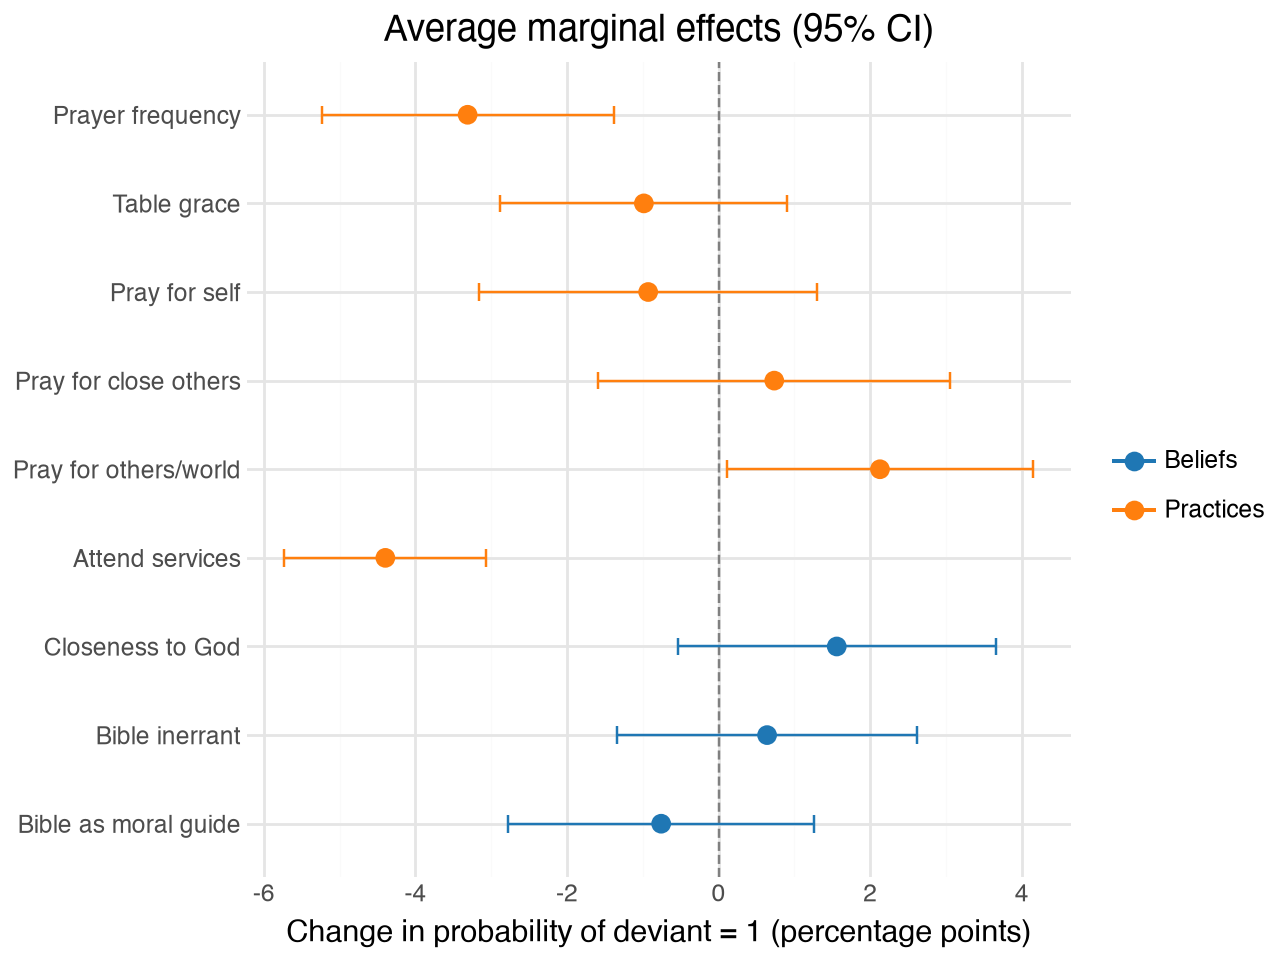

In [66]:
from plotnine import *
from marginaleffects import avg_comparisons
import pandas as pd
import numpy as np

belief_vars = ['god_close', 'bible_inerrant', 'bible_morality']   # everything else in rel_vars = practices

def plot_ame(model, variables, labels=None, title='Average marginal effects (95% CI)'):
    # Average marginal effects as a pandas dataframe
    ame_df = avg_comparisons(model, variables=variables).to_pandas()

    # Tag each row as a belief or a practice (before labels are renamed)
    ame_df['Type'] = np.where(ame_df['term'].isin(belief_vars), 'Beliefs', 'Practices')

    # Row labels: categorical terms use the contrast ("Black vs. White");
    # continuous terms use the variable name plus "(+1 unit)"
    ame_df['label'] = ame_df['contrast'].str.replace(' - ', ' vs. ', regex=False)
    cont = ame_df['contrast'].isin(['+1', '+1.0'])
    ame_df.loc[cont, 'label'] = ame_df.loc[cont, 'term'] + ' (+1 unit)'
    if labels:
        ame_df['label'] = ame_df['label'].replace(labels)       # optional nicer names

    # Probabilities to percentage points
    ame_df['pp'] = ame_df['estimate'] * 100
    ame_df['lo'] = ame_df['conf_low'] * 100
    ame_df['hi'] = ame_df['conf_high'] * 100

    # Reverse the order so the first term appears at the top of the plot
    ame_df['label'] = pd.Categorical(ame_df['label'], categories=ame_df['label'].tolist()[::-1])

    return (
        ggplot(ame_df, aes(x='pp', y='label', color='Type'))
        + geom_vline(xintercept=0, linetype='dashed', color='grey')   # no-effect line
        + geom_errorbarh(aes(xmin='lo', xmax='hi'), height=0.2)       # 95% CI
        + geom_point(size=3)
        + scale_color_manual(values={'Beliefs': '#1F77B4', 'Practices': '#FF7F0E'})   # blue / orange
        + labs(x='Change in probability of deviant = 1 (percentage points)', y='', title=title, color='')
        + theme_minimal()
    )

nice = {
    'pray_freq (+1 unit)': 'Prayer frequency',
    'table_grace (+1 unit)': 'Table grace',
    'pray_self (+1 unit)': 'Pray for self',
    'pray_close (+1 unit)': 'Pray for close others',
    'pray_others (+1 unit)': 'Pray for others/world',
    'attend_services (+1 unit)': 'Attend services',
    'god_close (+1 unit)': 'Closeness to God',
    'bible_inerrant (+1 unit)': 'Bible inerrant',
    'bible_morality (+1 unit)': 'Bible as moral guide',
}

plot_ame(logit_items, rel_vars, labels=nice)